In [ ]:
"""
%pip install tensorflow
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install pillow
%pip install pathlib
%pip install scikit-learn
%pip install torch
%pip install torch torchvision
%pip install openpyxl
%pip install lime
%pip install scikit-image
"""

   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
    --------------------------------------- 6.3/350.9 MB 38.6 MB/s eta 0:00:09
   -- ------------------------------------- 23.1/350.9 MB 60.8 MB/s eta 0:00:06
   ---- ----------------------------------- 37.7/350.9 MB 64.9 MB/s eta 0:00:05
   ------ --------------------------------- 52.7/350.9 MB 67.1 MB/s eta 0:00:05
   ------- -------------------------------- 68.2/350.9 MB 68.9 MB/s eta 0:00:05
   --------- ------------------------------ 84.1/350.9 MB 70.6 MB/s eta 0:00:04
   ----------- --------------------------- 101.7/350.9 MB 72.2 MB/s eta 0:00:04
   ------------- ------------------------- 118.0/350.9 MB 73.8 MB/s eta 0:00:04
   -------------- ------------------------ 134.7/350.9 MB 74.8 MB/s eta 0:00:03
   ---------------- ---------------------- 151.5/350.9 MB 75.6 MB/s eta 0:00:03
   ------------------ -------------------- 168.6/350.9 MB 76.4 MB/s eta 0:00:03
   -------------------- ------------------ 185.3/3

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


... (14 outputs left out)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report

import torch
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import f1_score

import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models import densenet121, DenseNet121_Weights
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Loading in the data

In [4]:
ROOT = Path(".")
IMG_DIR = ROOT / "Image"

print("folders in Image/:", sorted(p.name for p in IMG_DIR.iterdir()))   # a folder missing from FOLDERS (e.g. A-ROP, laser-treated) is left out of both tasks
FOLDERS = ["Normal", "Stage 1 ROP", "Stage 2 ROP", "Stage 3 ROP", "Stage 4 ROP", "Stage 5 ROP"]

# one row per image file, stacked across class folders
files = pd.concat(
    [pd.DataFrame({"image": [p.name for p in sorted((IMG_DIR / f).iterdir())
                             if p.suffix.lower() in {".jpg", ".jpeg"}],
                   "label": f})
     for f in FOLDERS],
    ignore_index=True,
)
files["path"] = [str(IMG_DIR / lab / name) for lab, name in zip(files["label"], files["image"])]

# attach patient metadata by filename
info = pd.read_excel(ROOT / "img_info.xlsx")
imgs = files.merge(info, on="image", how="left", validate="one_to_one").rename(columns={"image": "file"})
assert imgs["patient_id"].notna().all(), "some images are missing from img_info.xlsx"

# Mild = Stages 1-2, Moderate = Stage 3, Severe = Stages 4-5 (confirm against the dataset documentation)
SEVERITY = {"Stage 1 ROP": "Mild ROP", "Stage 2 ROP": "Mild ROP", "Stage 3 ROP": "Moderate ROP",
            "Stage 4 ROP": "Severe ROP", "Stage 5 ROP": "Severe ROP"}
imgs["severity"] = imgs["label"].map(SEVERITY)           
imgs["ROP"] = (imgs["label"] != "Normal").astype(int)    

print(pd.crosstab(imgs["label"], imgs["categories"], dropna=False))   # where are A-ROP / laser-treated images recorded?
print("imgs:", imgs.shape[0])
print("features:", imgs.columns)

folders in Image/: ['Normal', 'Stage 1 ROP', 'Stage 2 ROP', 'Stage 3 ROP', 'Stage 4 ROP', 'Stage 5 ROP']
categories   Stage 1 ROP  Stage 2 ROP  Stage 3 ROP  Stage 4 ROP  Stage 5 ROP  \
label                                                                          
Normal                 0            0            0            0            0   
Stage 1 ROP          236            0            0            0            0   
Stage 2 ROP            0          338            0            0            0   
Stage 3 ROP            0            0          241            0            0   
Stage 4 ROP            0            0            0           59            0   
Stage 5 ROP            0            0            0            0           30   

categories   normal  
label                
Normal          623  
Stage 1 ROP       0  
Stage 2 ROP       0  
Stage 3 ROP       0  
Stage 4 ROP       0  
Stage 5 ROP       0  
imgs: 1527
features: Index(['file', 'label', 'path', 'patient_id', 'gender', '

# Loading in the images

In [5]:
# Image dimensions when loaded in
size = 512

def load(p, size):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize(size))

# Opening the jpeg images as numpy arrays with the standardized size
imgs["image"] = imgs["path"].apply(lambda p: load(p, (size,size)))   

# Better to seperate the memory heavy image data from the rest of the data
X_all = np.stack(imgs["image"].values)
imgs = imgs.drop(columns="image")

# 5-fold cross-validation

In [6]:
# Similar to the regular KFold() function but able to handle stratification
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
# Initilizing as -1 makes overlooking skipped rows harder to overlook
imgs["fold"] = -1
# y = label to stratify on, every group stays in the same fold (so patients stay in the same fold)
for k, (train_idx, val_idx) in enumerate(sgkf.split(X=imgs, y=imgs["label"], groups=imgs["patient_id"])):
    # assigning images to a fold
    imgs.loc[val_idx, "fold"] = k

print("every image is in a fold:", (imgs["fold"] >= 0).all())
print("No patient is split between folds:", imgs.groupby("patient_id")["fold"].nunique().max() == 1)

every image is in a fold: True
No patient is split between folds: True


# Data pre-processing and augmentation transformers

In [ ]:
# Compose() chains a list of transforms into a single callable that applies them in order
# where v2 is what is being transformed
train_tf = v2.Compose([
    v2.ToImage(),                                    # HWC uint8 array -> CHW tensor
    v2.ToDtype(torch.float32, scale=True),           # intensity normalization: [0, 255] -> [0, 1]
    v2.RandomHorizontalFlip(p=0.5),                  # random horizontal flip
    v2.RandomAffine(degrees=5, scale=(0.9, 1.1),     # rotation in [-5, 5] deg and scale in [0.9, 1.1], one resampling step
                    interpolation=v2.InterpolationMode.BILINEAR, fill=0),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.0),
])

val_tf = v2.Compose([                                # validation: normalization only
    v2.ToImage(),                                    # no augmentation
    v2.ToDtype(torch.float32, scale=True),
])

# Assigning a dataset for each task

In [8]:
# Class names for later reports
OCC_CLASSES = ["Normal", "ROP"]                                  
SEV_MAP = {"Mild ROP": 0, "Moderate ROP": 1, "Severe ROP": 2}
SEV_CLASSES = list(SEV_MAP)

# ROP occurence task
occ_df = imgs.assign(y=imgs["ROP"])
occ_df.to_csv("occ_df.csv", index=True)
# severity task
sev_df = imgs[imgs["severity"].notna()].assign(
    # encoding
    y=lambda d: d["severity"].map({"Mild ROP": 0, "Moderate ROP": 1, "Severe ROP": 2}))
sev_df.to_csv("sev_df.csv", index=True)

print("-------[Occurence Task]-------")
print("occurence task unique patients:", occ_df["patient_id"].unique().shape[0])
print("occurence task images:", occ_df.shape[0])
print("num classes:", occ_df["ROP"].unique().shape[0])
print(pd.crosstab(imgs["ROP"], imgs["fold"]))
print("\n")
print("-------[Severity Task]-------")
print("severity task unique patients:", sev_df["patient_id"].unique().shape[0])
print("severity task images:", sev_df.shape[0])
print("num classes:", sev_df["severity"].unique().shape[0])
print(pd.crosstab(imgs["severity"], imgs["fold"]))

-------[Occurence Task]-------
occurence task unique patients: 916
occurence task images: 1527
num classes: 2
fold    0    1    2    3    4
ROP                          
0     124  125  124  125  125
1     182  181  181  180  180


-------[Severity Task]-------
severity task unique patients: 550
severity task images: 904
num classes: 3
fold            0    1    2    3    4
severity                             
Mild ROP      116  114  115  114  115
Moderate ROP   48   49   48   48   48
Severe ROP     18   18   18   18   17


# Image Loader

In [9]:
class ROPDataset(Dataset):
    """Hands the DataLoader one (image, label) pair at a time, applying the transform on the fly."""

    def __init__(self, X, idx, y, tf):
        # X   : the full image array (1527, 512, 512, 3), uint8. Stored by reference, not copied.
        # idx : row numbers in X that belong to this dataset (e.g. this fold's training rows)
        # y   : labels for those same rows, in the same order as idx
        # tf  : transform pipeline (train_tf or val_tf)
        # np.asarray turns the pandas Index / Series into plain numpy arrays
        self.X, self.idx, self.y, self.tf = X, np.asarray(idx), np.asarray(y), tf

    def __len__(self):
        # the DataLoader calls this to know how many samples there are (which sets batches per epoch)
        return len(self.idx)

    def __getitem__(self, i):
        # i is a position within this dataset (0 .. len-1), not a row number in X.
        # self.idx[i] translates it to the row in X, and self.X[...] is one (512, 512, 3) uint8 image.
        # self.tf(...) returns a float tensor (3, 512, 512). The random steps in train_tf are
        # re-drawn on every call, so the same image looks different each epoch (X itself isn't modified).
        # int(self.y[i]) is a plain Python int label; the DataLoader stacks these into a tensor.
        return self.tf(self.X[self.idx[i]]), int(self.y[i])


def make_loaders(df, k, bs=16):
    # df: occ_df or sev_df (needs "fold" and "y" columns). k: the fold held out for validation.
    tr, va = df[df["fold"] != k], df[df["fold"] == k]    # four folds to train on, one to validate on

    # tr.index holds the original row numbers in imgs / X_all (they survive the filtering),
    # and tr["y"] holds their labels in the same order
    train_dl = DataLoader(ROPDataset(X_all, tr.index, tr["y"], train_tf), batch_size=bs, shuffle=True)  # new order each epoch
    val_dl   = DataLoader(ROPDataset(X_all, va.index, va["y"], val_tf),   batch_size=bs)               # no shuffle: order stays fixed
    # DataLoader() provides effecient data handling during training and evaluation
    return train_dl, val_dl

# Testing augmentation

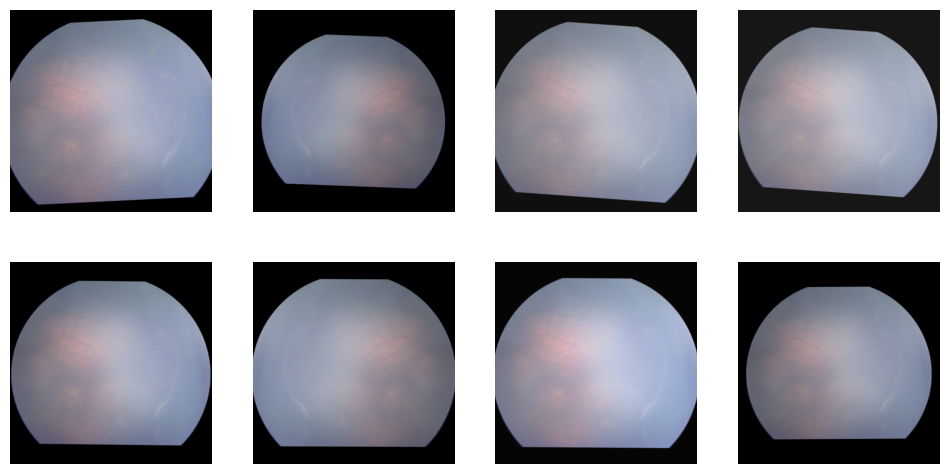

In [10]:
# X_all is all the images only
img = X_all[sev_df.index[0]] # gets an index for the image data
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
# Do 8 times for the same image
for ax in axes.flat:
    ax.imshow(train_tf(img).permute(1, 2, 0).clamp(0, 1).numpy())
    # train_tf applies the transforms to a given image (roation, color jitter, etc)
    # permute() changes the tensors shape from (channels, height, width) to (hight, width, channels)
    # clamp(0,1) ensures the pixels are within a valid range for images
    # numpy() converts the tensor to a numpy array
    ax.axis("off")

# Checks

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

train_dl, val_dl = make_loaders(sev_df, k=0)
xb, yb = next(iter(train_dl))
print(xb.shape, xb.dtype, yb.dtype, float(xb.min()), float(xb.max()))
# expect torch.Size([16, 3, 512, 512]) torch.float32 torch.int64, values within [0, 1]

device: cuda
torch.Size([16, 3, 512, 512]) torch.float32 torch.int64 0.0 1.0


# Model

In [12]:
class ImageNetNorm(nn.Module):
    """Standardizes inputs with the statistics the pretrained backbone was trained on."""
    def __init__(self):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return (x - self.mean) / self.std

# The three pretrained ImageNet backbones that get compared (same folds, preprocessing and augmentation for each)
ARCHS = ["resnet18", "densenet121", "efficientnet_b0"]

def build_model(n_classes, arch="resnet18", pretrained=True):
    """Pretrained backbone with its last layer swapped for a new head with n_classes outputs."""
    if arch == "resnet18":
        net = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)               # downloads weights once
        net.fc = nn.Linear(net.fc.in_features, n_classes)                                       # 512 features -> n_classes logits
    elif arch == "densenet121":
        net = densenet121(weights=DenseNet121_Weights.DEFAULT if pretrained else None)
        net.classifier = nn.Linear(net.classifier.in_features, n_classes)                       # 1024 features -> n_classes logits
    elif arch == "efficientnet_b0":
        net = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        net.classifier[1] = nn.Linear(net.classifier[1].in_features, n_classes)                 # 1280 features -> n_classes logits (keeps the dropout before it)
    else:
        raise ValueError(f"unknown architecture: {arch}")
    return nn.Sequential(ImageNetNorm(), net).to(device)

# Training and cross-validation functions

In [33]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

def run_epoch(model, dl, loss_fn, opt=None):
    training = opt is not None
    model.train(training)                          # eval mode freezes batch-norm statistics
    total, probs, ys = 0.0, [], []
    with torch.set_grad_enabled(training):         # no gradients needed for validation
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            with torch.autocast("cuda", dtype=torch.bfloat16):   # forward pass in bf16 to roughly halve activation memory
                out = model(xb)
            out = out.float()                      # logits back to fp32, so the loss and softmax run at full precision
            loss = loss_fn(out, yb)
            if training:
                opt.zero_grad(); loss.backward(); opt.step()
            else:
                probs.append(out.softmax(1).cpu()); ys.append(yb.cpu())
            total += loss.item() * len(yb)
    n = len(dl.dataset)
    return total / n if training else (total / n, torch.cat(probs).numpy(), torch.cat(ys).numpy())

def train_fold(df, k, n_classes, epochs, arch="resnet18", lr=1e-4, bs=16, pretrained=True, tag="model", monitor="loss"):
    """Best-epoch checkpointing. monitor: "loss" (lowest val loss), "f1" (highest val macro-F1) or "last" (final epoch, no choice made on the held-out fold).
    Saves the best epoch's weights and returns that same epoch's validation probabilities."""
    train_dl, val_dl = make_loaders(df, k, bs)
    model = build_model(n_classes, arch, pretrained)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()
    best_score, best_ep, best_probs = None, -1, None
    for ep in range(epochs):
        tl = run_epoch(model, train_dl, loss_fn, opt)
        sched.step()
        vl, probs, ys = run_epoch(model, val_dl, loss_fn)
        pred = probs.argmax(1)
        acc, f1 = (pred == ys).mean(), f1_score(ys, pred, average="macro")
        score = -vl if monitor == "loss" else (f1 if monitor == "f1" else ep)   # monitor="last": final epoch always wins
        improved = best_score is None or score > best_score
        if improved:
            best_score, best_ep, best_probs = score, ep + 1, probs
            torch.save(model.state_dict(), MODEL_DIR / f"{tag}_fold{k}.pt")
        print(f"fold {k} epoch {ep+1}/{epochs}: train loss {tl:.3f} | val loss {vl:.3f} | val acc {acc:.3f} | val macro-F1 {f1:.3f}" + ("  <- best" if improved else ""))
    print(f"fold {k}: kept epoch {best_ep} (monitor={monitor})")
    return best_probs                              # best-epoch validation probabilities, in va.index order

def cross_validate(df, n_classes, epochs, tag="model", **kw):
    oof = np.zeros((len(imgs), n_classes))         # out-of-fold probabilities, one row per image
    for k in range(5):
        oof[df.index[df["fold"] == k].to_numpy()] = train_fold(df, k, n_classes, epochs, tag=tag, **kw)
    return oof

def load_fold_model(tag, k, n_classes, arch="densenet121"):
    """Rebuild the architecture and load the weights saved for fold k (eval mode)."""
    model = build_model(n_classes, arch, pretrained=False)
    model.load_state_dict(torch.load(MODEL_DIR / f"{tag}_fold{k}.pt", map_location=device))
    return model.eval()

# Occurence: training and cross-validation

In [14]:
"""
oof_occ = {}   # architecture name -> out-of-fold probabilities
for arch in ARCHS:
    oof_occ[arch] = cross_validate(occ_df, n_classes=2, epochs=50, arch=arch, tag=f"occ_{arch}", monitor="last")
    np.save(f"oof_occ_{arch}.npy", oof_occ[arch])   # so a kernel crash only loses the architecture that was running
# if a larger architecture runs out of GPU memory, add bs=8 to cross_validate(...)
"""

'\noof_occ = {}   # architecture name -> out-of-fold probabilities\nfor arch in ARCHS:\n    oof_occ[arch] = cross_validate(occ_df, n_classes=2, epochs=50, arch=arch, tag=f"occ_{arch}", monitor="last")\n    np.save(f"oof_occ_{arch}.npy", oof_occ[arch])   # so a kernel crash only loses the architecture that was running\n# if a larger architecture runs out of GPU memory, add bs=8 to cross_validate(...)\n'

# Severity: training and cross-validation

In [15]:
"""
# monitor="last" keeps the final epoch, so no epoch is chosen using the held-out fold that gets reported
oof_sev = {}   # architecture name -> out-of-fold probabilities
for arch in ARCHS:
    oof_sev[arch] = cross_validate(sev_df, n_classes=3, epochs=50, arch=arch, tag=f"sev_{arch}", monitor="last")
    np.save(f"oof_sev_{arch}.npy", oof_sev[arch])
"""

'\n# monitor="last" keeps the final epoch, so no epoch is chosen using the held-out fold that gets reported\noof_sev = {}   # architecture name -> out-of-fold probabilities\nfor arch in ARCHS:\n    oof_sev[arch] = cross_validate(sev_df, n_classes=3, epochs=50, arch=arch, tag=f"sev_{arch}", monitor="last")\n    np.save(f"oof_sev_{arch}.npy", oof_sev[arch])\n'

In [16]:
import torch.nn.functional as F
from matplotlib import colormaps

# Last conv-feature layer for each architecture (inside the Sequential's [1] = the torchvision net)
def gradcam_target_layer(model, arch):
    net = model[1]
    if arch == "resnet18":
        return net.layer4[-1]
    if arch == "densenet121":
        return net.features
    if arch == "efficientnet_b0":
        return net.features[-1]
    raise ValueError(f"unknown architecture: {arch}")

class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model.eval(), None, None
        self.h = layer.register_forward_hook(self._fwd)

    def _fwd(self, module, inp, out):
        self.acts = out.detach().clone()                         # clone: torchvision ReLUs run in-place afterwards
        out.register_hook(lambda g: setattr(self, "grads", g.detach()))

    def __call__(self, x, class_idx=None):
        """x: (1,3,H,W) float in [0,1] on `device` (the model normalizes internally).
        Returns (cam in [0,1] at input resolution as (H,W) numpy, predicted class, class probabilities)."""
        self.model.zero_grad()
        with torch.enable_grad():
            logits = self.model(x.requires_grad_(False)).float()
            probs = logits.softmax(1)[0].detach().cpu().numpy()
            cls = int(logits.argmax(1)) if class_idx is None else class_idx
            logits[0, cls].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)            # GAP of gradients = channel weights
        cam = F.relu((w * self.acts).sum(1, keepdim=True))       # (1,1,h,w)
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam / (cam.max() + 1e-8)).cpu().numpy()
        return cam, cls, probs

    def close(self):
        self.h.remove()

def show_gradcam(img_uint8, cam, title="", alpha=0.4):
    heat = colormaps["jet"](np.uint8(255 * cam))[..., :3]
    overlay = np.clip((1 - alpha) * (img_uint8 / 255.0) + alpha * heat, 0, 1)
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    for a, im, t in zip(ax, [img_uint8, cam, overlay], ["image", "Grad-CAM", "overlay"]):
        a.imshow(im, cmap="jet" if t == "Grad-CAM" else None); a.set_title(t); a.axis("off")
    fig.suptitle(title); plt.show()

In [31]:
def explain(df, row, tag, n_classes, arch="densenet121", class_names=None, class_idx=None):
    """row = index into imgs / X_all. Uses the model from the fold where that image was held out."""
    k = int(df.loc[row, "fold"])
    model = load_fold_model(tag, k, n_classes, arch)             # loads models/{tag}_fold{k}.pt
    cam_fn = GradCAM(model, gradcam_target_layer(model, arch))
    img = X_all[row]                                             # (512,512,3) uint8
    x = val_tf(img).unsqueeze(0).to(device)
    cam, cls, probs = cam_fn(x, class_idx)
    cam_fn.close()
    name = class_names[cls] if class_names else cls
    show_gradcam(img, cam, f"{df.loc[row, 'label']} | pred: {name} ({probs[cls]:.2f}) | fold {k}")
    return cam

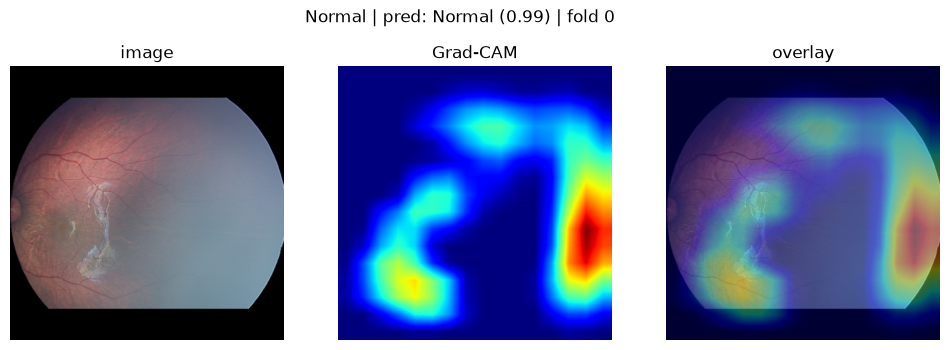

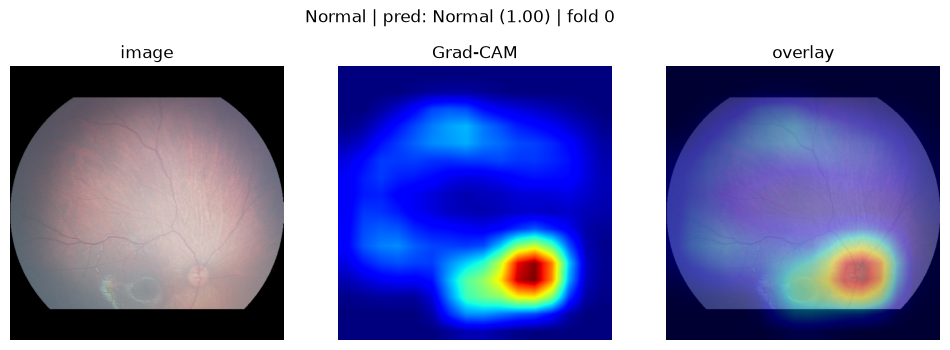

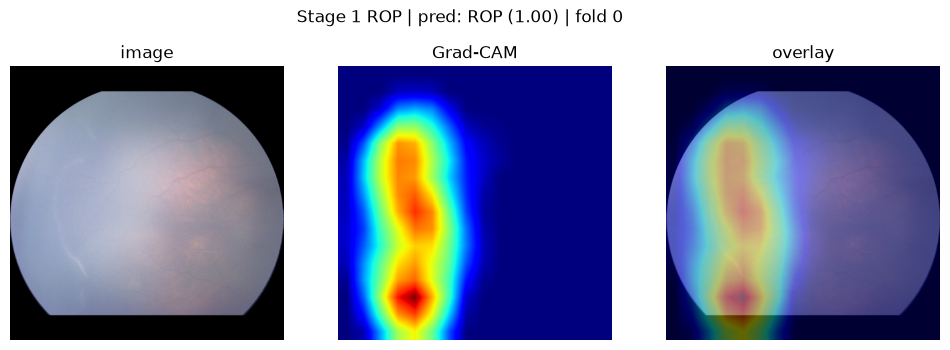

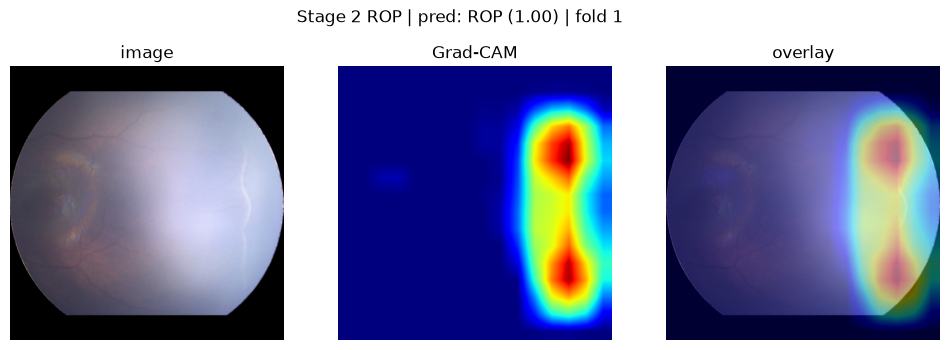

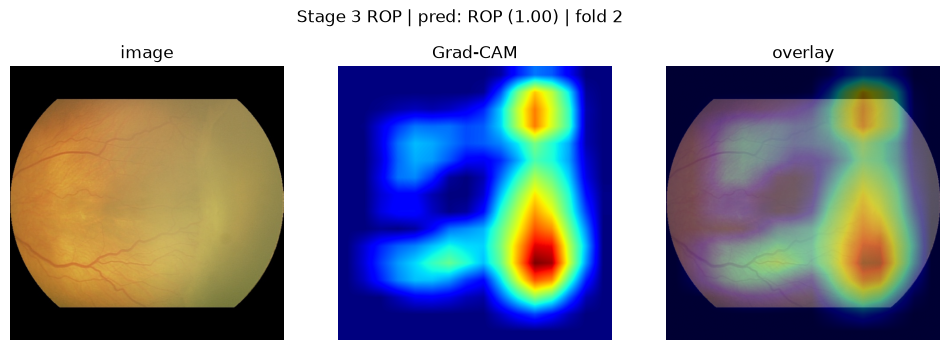

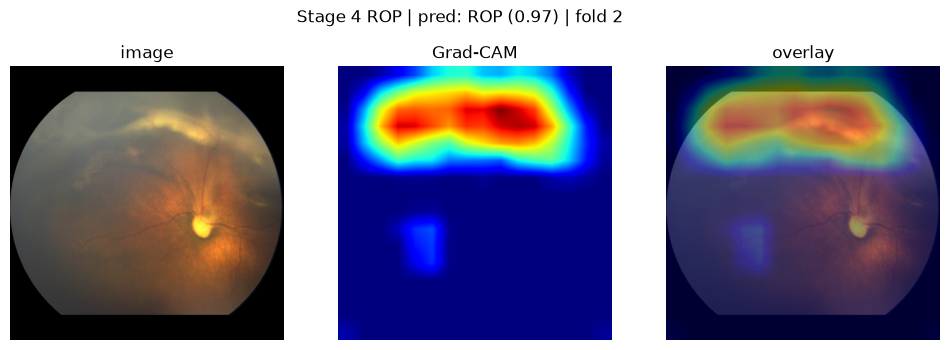

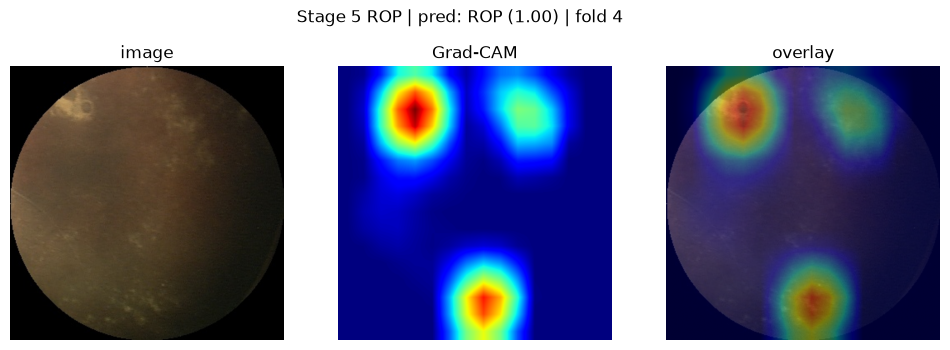

In [21]:
# Occurrence, a Stage 3 image from the ROP-vs-normal model
row = occ_df.index[occ_df["label"] == "Normal"][0]
explain(occ_df, row, tag="occ_densenet121", n_classes=2, arch="densenet121", class_names=OCC_CLASSES);
row = occ_df.index[occ_df["label"] == "Normal"][1]
explain(occ_df, row, tag="occ_densenet121", n_classes=2, arch="densenet121", class_names=OCC_CLASSES);
row = occ_df.index[occ_df["label"] == "Stage 1 ROP"][0]
explain(occ_df, row, tag="occ_densenet121", n_classes=2, arch="densenet121", class_names=OCC_CLASSES);
row = occ_df.index[occ_df["label"] == "Stage 2 ROP"][0]
explain(occ_df, row, tag="occ_densenet121", n_classes=2, arch="densenet121", class_names=OCC_CLASSES);
row = occ_df.index[occ_df["label"] == "Stage 3 ROP"][0]
explain(occ_df, row, tag="occ_densenet121", n_classes=2, arch="densenet121", class_names=OCC_CLASSES);
row = occ_df.index[occ_df["label"] == "Stage 4 ROP"][0]
explain(occ_df, row, tag="occ_densenet121", n_classes=2, arch="densenet121", class_names=OCC_CLASSES);
row = occ_df.index[occ_df["label"] == "Stage 5 ROP"][0]
explain(occ_df, row, tag="occ_densenet121", n_classes=2, arch="densenet121", class_names=OCC_CLASSES);

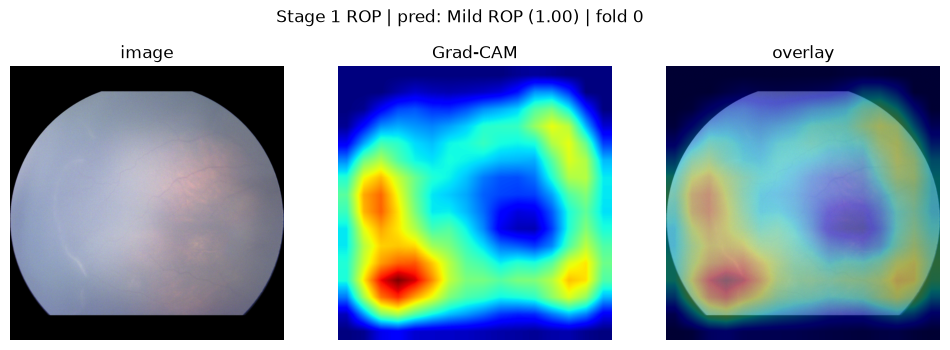

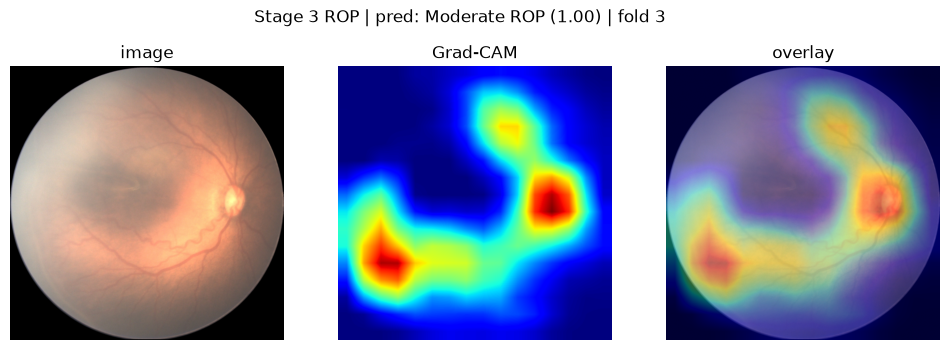

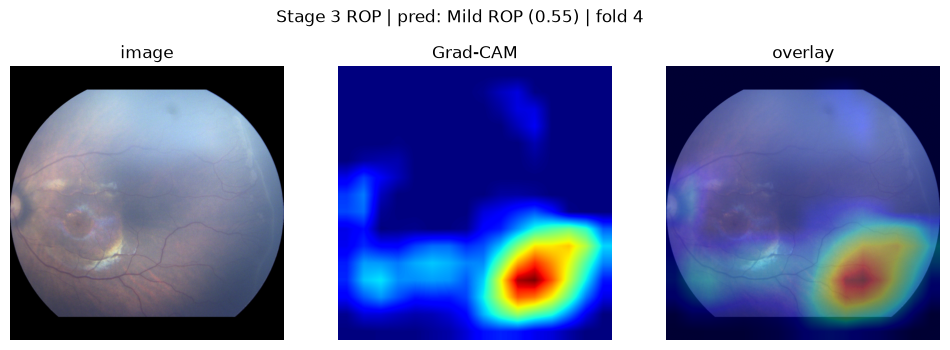

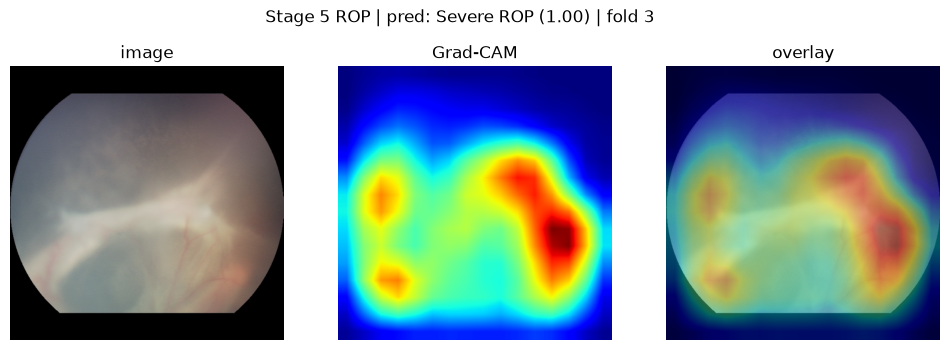

In [26]:
# Severity
row = sev_df.index[0]
explain(sev_df, row, tag="sev_densenet121", n_classes=3, arch="densenet121", class_names=SEV_CLASSES);
row = sev_df.index[600]
explain(sev_df, row, tag="sev_densenet121", n_classes=3, arch="densenet121", class_names=SEV_CLASSES);
row = sev_df.index[602]
explain(sev_df, row, tag="sev_densenet121", n_classes=3, arch="densenet121", class_names=SEV_CLASSES);
row = sev_df.index[901]
explain(sev_df, row, tag="sev_densenet121", n_classes=3, arch="densenet121", class_names=SEV_CLASSES);

In [30]:
def wrong_rows(df, oof, n_classes):
    """Row indices (into imgs / X_all) where the out-of-fold prediction != true label."""
    pred = oof[df.index.to_numpy()].argmax(1)
    return df.index[pred != df["y"].to_numpy()]

def explain_wrong(df, oof, tag, n_classes, arch="densenet121", class_names=None, per_label=2):
    wrong = wrong_rows(df, oof, n_classes)
    print(f"{len(wrong)} / {len(df)} misclassified")
    for lab in df["label"].unique():                      # a few per original stage
        for row in wrong[df.loc[wrong, "label"] == lab][:per_label]:
            explain(df, row, tag, n_classes, arch, class_names)

oof_occ_dense = np.load("oof_occ_densenet121.npy")
oof_sev_dense = np.load("oof_sev_densenet121.npy")

32 / 1527 misclassified


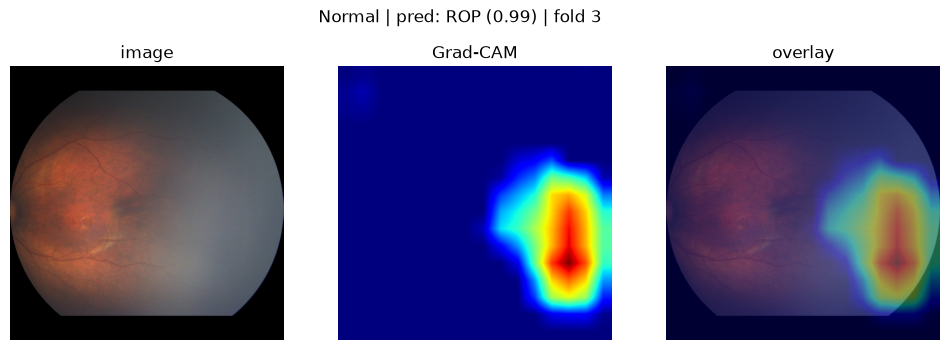

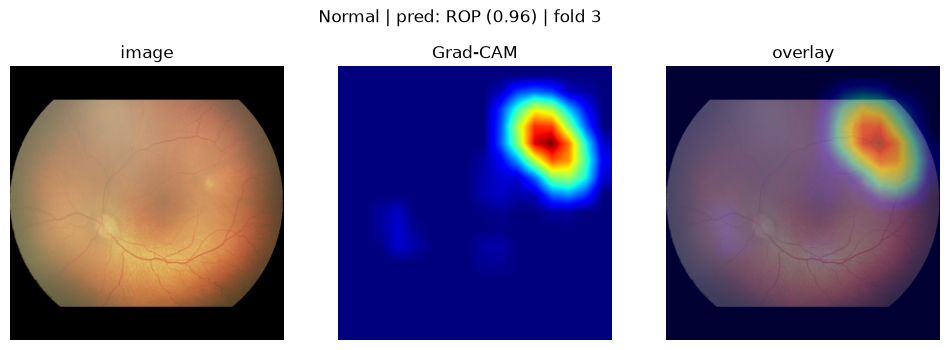

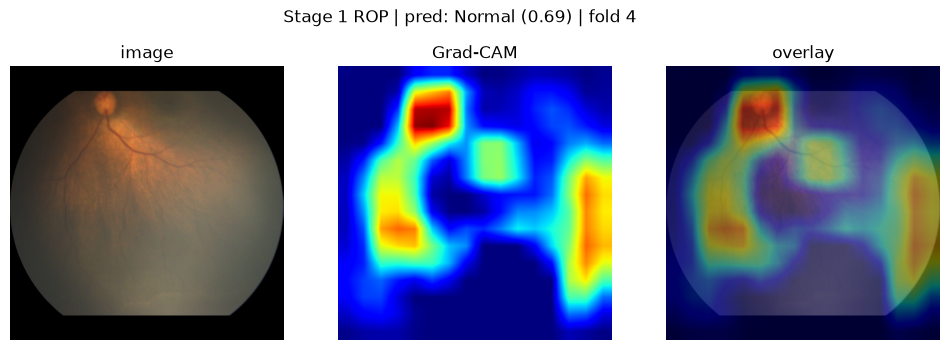

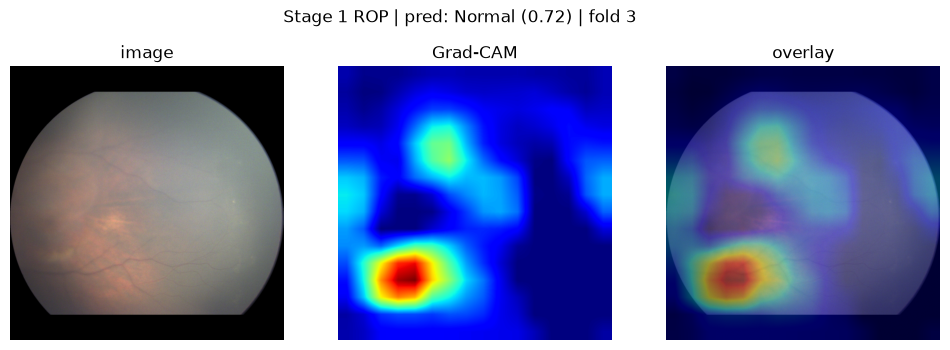

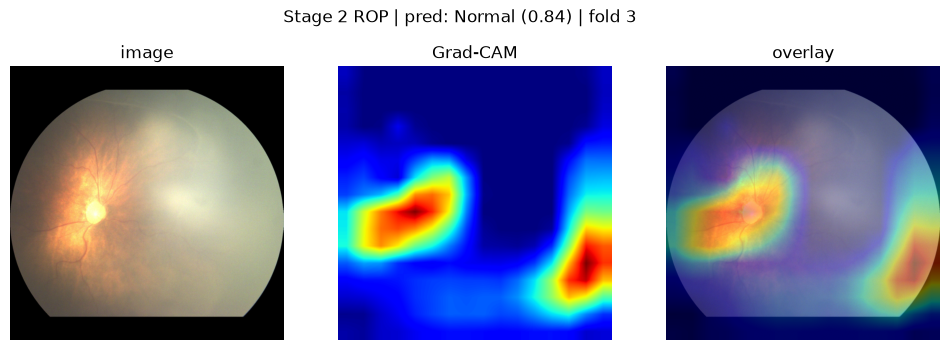

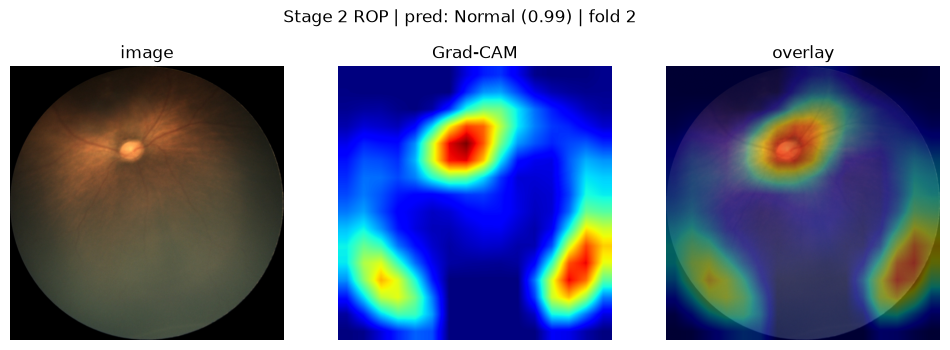

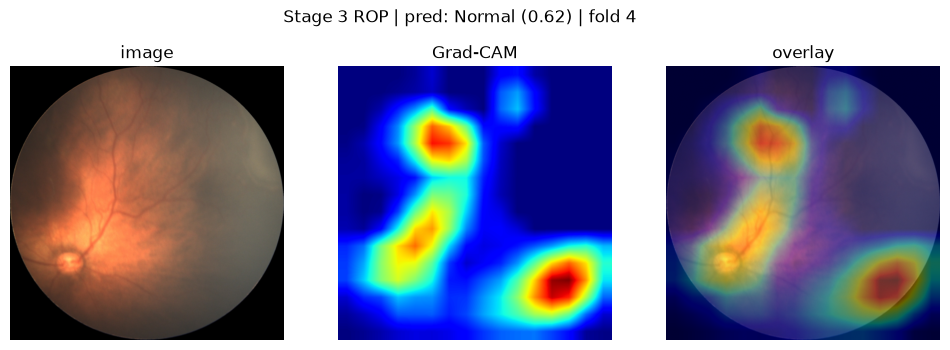

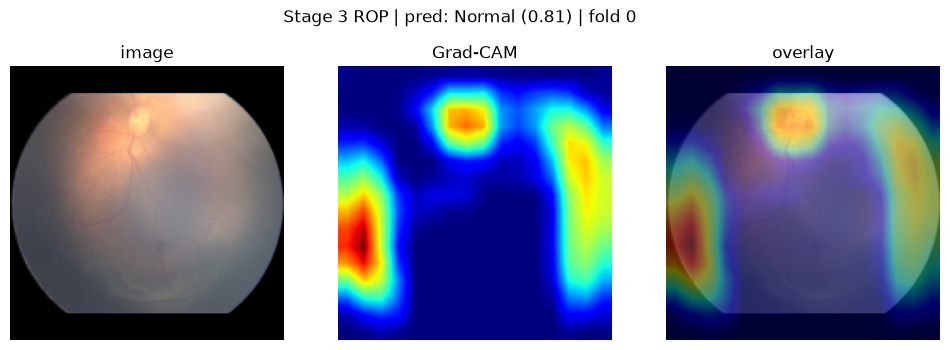

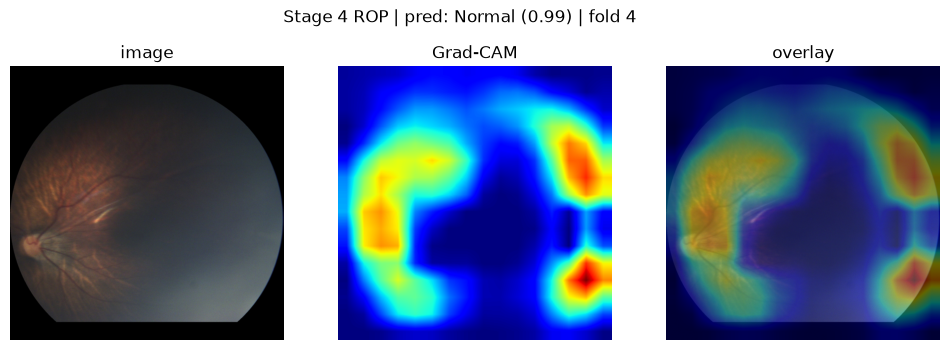

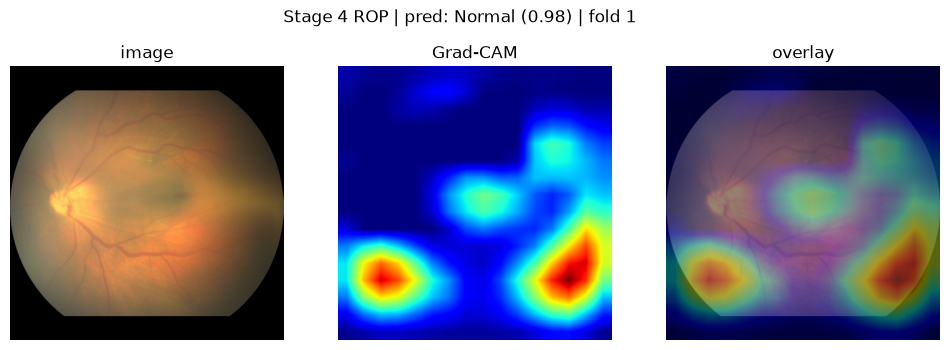

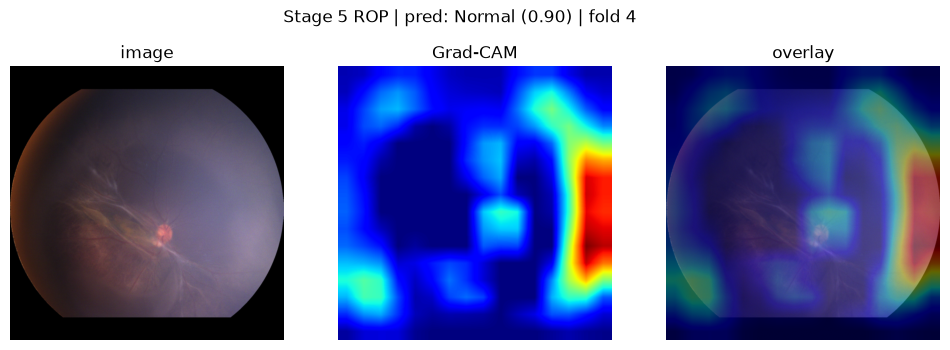

In [24]:
# Occurrence: misclassified images, up to 2 per stage/Normal
explain_wrong(occ_df, oof_occ_dense, "occ_densenet121", 2, "densenet121", OCC_CLASSES)

117 / 904 misclassified


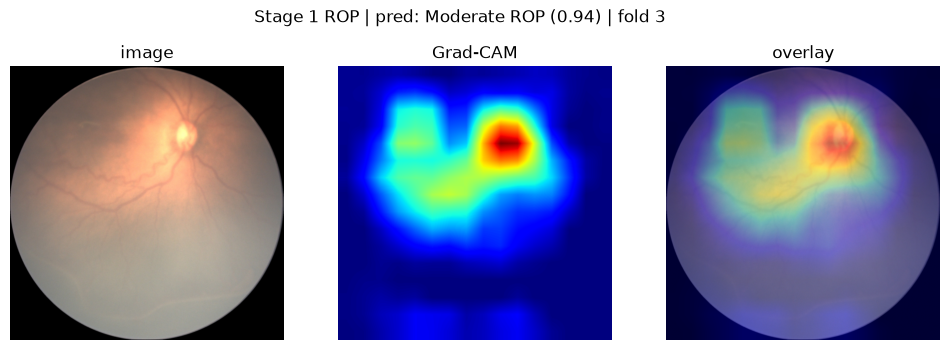

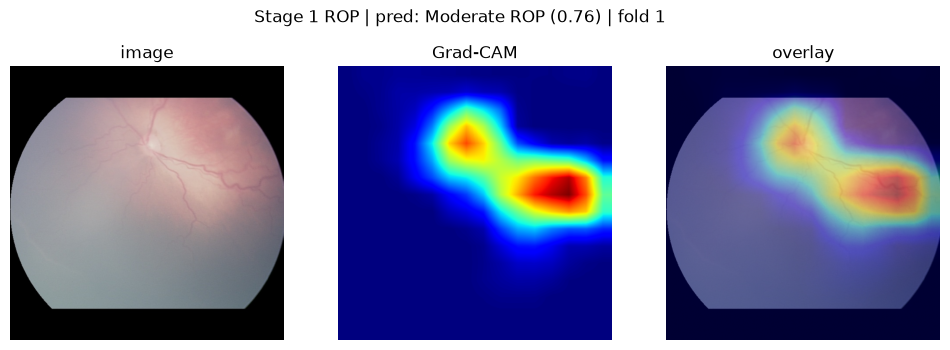

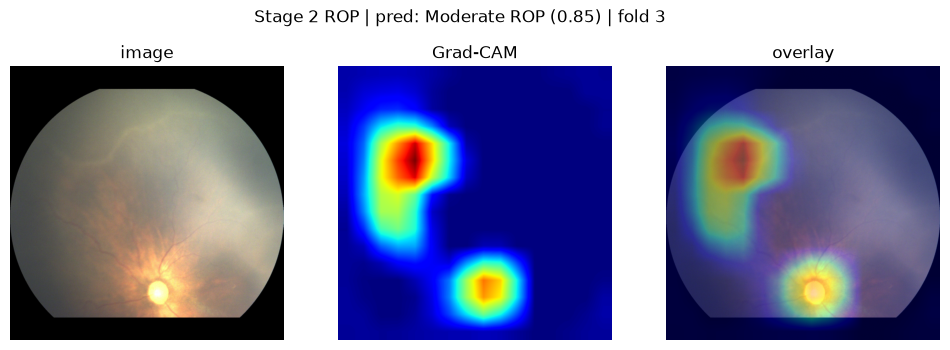

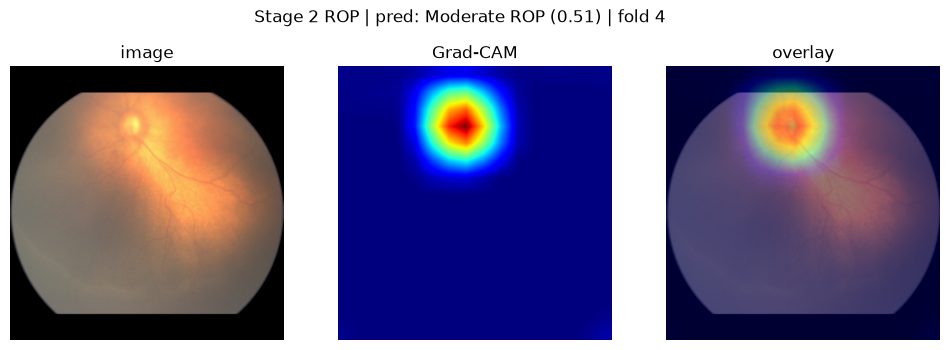

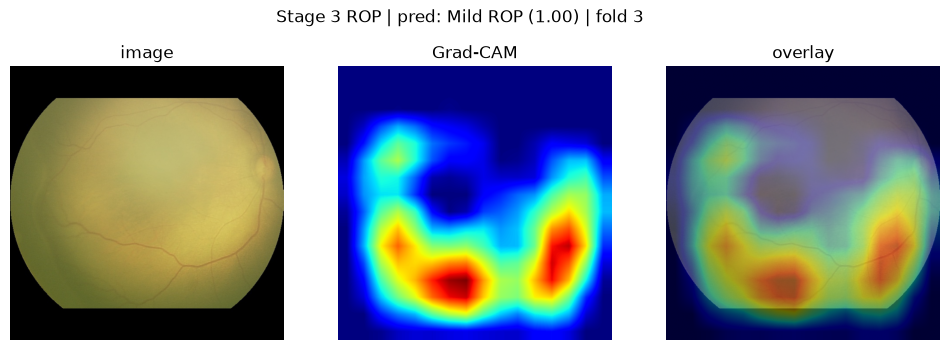

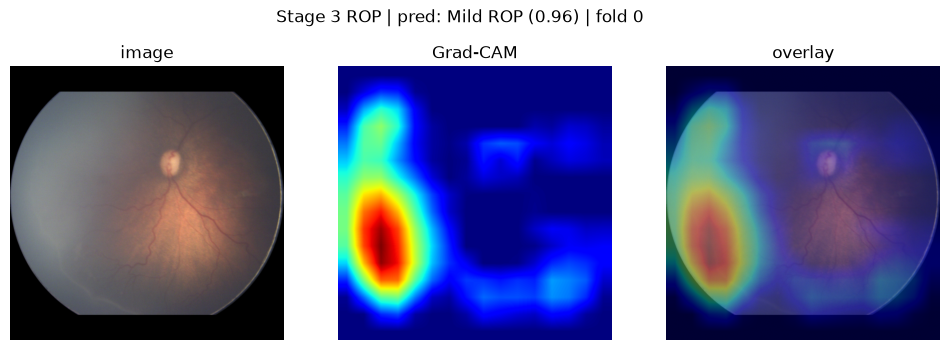

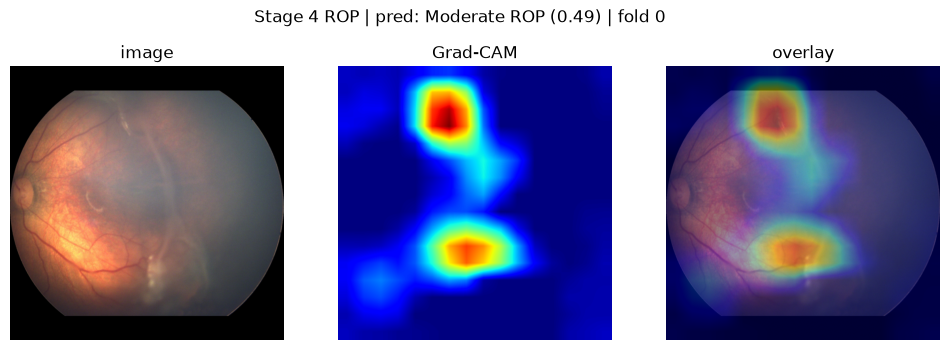

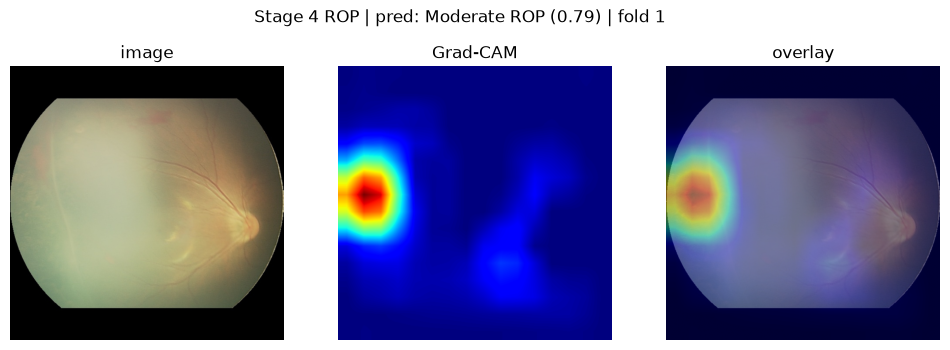

In [35]:
# Severity: misclassified images, up to 2 per stage
explain_wrong(sev_df, oof_sev_dense, "sev_densenet121", 3, "densenet121", SEV_CLASSES)